# PD05 · Particionamiento y comparación pandas–Polars

Continuación de PD01–PD03 basada en las clases del 9 y 10 de octubre de 2026. Tiempo orientativo: 210 minutos, con el entorno y los datos preparados.

Copia esta plantilla a `soluciones/` conservando su nombre. Escribe allí el código y las interpretaciones. Las celdas iniciales muestran las lecturas; las actividades quedan a tu cargo. Antes de entregar, reinicia el kernel y ejecuta todas las celdas en orden.

Utiliza directamente las API de pandas, Polars y GeoPandas. Mantén visibles las conversiones, máscaras, agrupaciones, uniones y exportaciones. No uses `talleres.py`, `pqrs_talleres.py`, comandos de shell ni funciones que resuelvan varias etapas sin mostrar su implementación. Un bucle de medición es válido si su cuerpo contiene las operaciones que estás midiendo. No instales paquetes desde el notebook.

[Índice](../ejercicios/README.md) · [Pandas](../docs/manual-pandas.md) · [Polars](../docs/manual-polars.md) · [GeoPandas](../docs/manual-geopandas.md)

## Ubicación de trabajo

Abre Jupyter desde la raíz del repositorio con el entorno del curso activo. Cambia `REPO` por la ruta real de tu copia. Las rutas son explícitas y funcionan tanto desde `ejercicios/` como desde `soluciones/`. Si falta un archivo, revisa su ubicación; no sustituyas silenciosamente la entrada por otro dataset.

## Pregunta y preparación

¿Cómo cambian lectura, escritura y procesamiento al variar formato, particionamiento y motor?

Requiere el Parquet completo y la capa municipal del GeoPackage de PD04 y las dependencias del entorno del curso: `requirements.txt` y `requirements_pqrs.txt`. Trabaja en CPU. No dupliques filas para simular volumen. Esta actividad estudia los resultados de este equipo y estos datos.

Las lecturas siguientes son directas. Para comparar CSV más adelante, escribe explícitamente `pd.read_csv` y `pl.read_csv`, sus separadores, política de nulos y tipos. No uses inferencia diferente de tipos como si fuera trabajo equivalente.

El particionamiento será manual: un `groupby` divide la tabla y cada grupo se escribe en un archivo independiente. Los valores de las claves permanecen dentro de cada archivo. Un inventario CSV registra dónde está cada parte; no se configura un catálogo ni un motor de particiones.


In [1]:
import os
import time
import platform
import pandas as pd
import polars as pl
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

REPO = "/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate"
INPUT = REPO + "/kit/salidas/soluciones/PD04/analisis_integrados.parquet"
OUT = REPO + "/kit/salidas/soluciones/PD05"
os.makedirs(OUT, exist_ok=True)
print("Entrada:", INPUT)
print("Salidas:", OUT)
print(platform.platform())
print("pandas:", pd.__version__, "Polars:", pl.__version__, "GeoPandas:", gpd.__version__)

Entrada: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04/analisis_integrados.parquet
Salidas: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD05
Linux-6.18.54.1-microsoft-standard-WSL2-x86_64-with-glibc2.43
pandas: 2.2.3 Polars: 1.35.2 GeoPandas: 1.2.0


In [6]:
datos_pd = pd.read_parquet(INPUT, engine="pyarrow")
display(datos_pd.head())
print(datos_pd.shape)
print(datos_pd.dtypes)

,dpto_ccdgo,mpio_ccdgo,mpio_cdpmp,dpto_cnmbr,mpio_cnmbr,mpio_crslc,mpio_tipo,mpio_narea,mpio_nano,shape_Leng,shape_Area,codigo_municipio,total_analisis,ph_validos,media_ph,anio,_merge,area_ha,area_intersectada_ha
0,05,001,05001,ANTIOQUIA,MEDELLÍN,1965,MUNICIPIO,374.741484,2025,1.035380,0.030608,05001,NaN,NaN,NaN,NaN,left_only,37474.148450,0
1,05,002,05002,ANTIOQUIA,ABEJORRAL,1814,MUNICIPIO,506.959782,2024,1.158504,0.041384,05002,NaN,NaN,NaN,NaN,left_only,50695.978227,0
2,05,004,05004,ANTIOQUIA,ABRIAQUÍ,1912,MUNICIPIO,296.974188,2025,0.810667,0.024253,05004,NaN,NaN,NaN,NaN,left_only,29697.418845,0
3,05,021,05021,ANTIOQUIA,ALEJANDRÍA,Decreto departamental 304 de 1907,MUNICIPIO,128.856431,2024,0.705200,0.010535,05021,NaN,NaN,NaN,NaN,left_only,12885.643129,0
4,05,030,05030,ANTIOQUIA,AMAGÁ,1912,MUNICIPIO,84.117145,2024,0.445533,0.006867,05030,NaN,NaN,NaN,NaN,left_only,8411.714470,0


(1122, 19)
dpto_ccdgo               object
mpio_ccdgo               object
mpio_cdpmp               object
dpto_cnmbr               object
mpio_cnmbr               object
mpio_crslc               object
mpio_tipo                object
mpio_narea              float64
mpio_nano                 int32
shape_Leng              float64
shape_Area              float64
codigo_municipio         object
total_analisis          float64
ph_validos              float64
media_ph                float64
anio                    float64
_merge                   object
area_ha                 float64
area_intersectada_ha      int64
dtype: object


In [7]:
datos_pl = pl.read_parquet(INPUT)
print(datos_pl.head())
print(datos_pl.shape)
print(datos_pl.schema)

shape: (5, 19)
┌────────────┬────────────┬────────────┬────────────┬───┬──────┬───────────┬───────────┬───────────┐
│ dpto_ccdgo ┆ mpio_ccdgo ┆ mpio_cdpmp ┆ dpto_cnmbr ┆ … ┆ anio ┆ _merge    ┆ area_ha   ┆ area_inte │
│ ---        ┆ ---        ┆ ---        ┆ ---        ┆   ┆ ---  ┆ ---       ┆ ---       ┆ rsectada_ │
│ str        ┆ str        ┆ str        ┆ str        ┆   ┆ f64  ┆ str       ┆ f64       ┆ ha        │
│            ┆            ┆            ┆            ┆   ┆      ┆           ┆           ┆ ---       │
│            ┆            ┆            ┆            ┆   ┆      ┆           ┆           ┆ i64       │
╞════════════╪════════════╪════════════╪════════════╪═══╪══════╪═══════════╪═══════════╪═══════════╡
│ 05         ┆ 001        ┆ 05001      ┆ ANTIOQUIA  ┆ … ┆ null ┆ left_only ┆ 37474.148 ┆ 0         │
│            ┆            ┆            ┆            ┆   ┆      ┆           ┆ 45        ┆           │
│ 05         ┆ 002        ┆ 05002      ┆ ANTIOQUIA  ┆ … ┆ null ┆ left_only ┆

## 1. Contrato común y consulta · 25 minutos

Proyecta en ambos motores las mismas columnas: `id_fila`, `anio`, `codigo_departamento`, `codigo_municipio`, `ph` y `ph_valido`. Mantén todas las filas. Declara tipos equivalentes, cómo representar nulos en CSV y cómo restaurar códigos con ceros iniciales.

Elige un año y departamento presentes. Filtra y agrupa por municipio para obtener total de análisis, cantidad de pH válidos y media del pH válido. Conserva el grupo municipal ausente, si existe, y la media ausente cuando no hay pH válidos. En pandas utiliza `groupby(..., dropna=False)`; en Polars comprueba el tratamiento equivalente de claves nulas.

**Control:** compara claves y conteos exactos; medias con tolerancia absoluta 0.000001 y relativa cero. Ordena antes de comparar y comprueba también dónde aparecen nulos.

In [11]:


# 1. Columnas reales basadas en el esquema de analisis_integrados.parquet
COLUMNAS_CONTRATO = ["anio", "dpto_ccdgo", "codigo_municipio", "media_ph", "ph_validos", "total_analisis"]

TIPOS_PANDAS = {
    "anio": "Int64",
    "dpto_ccdgo": "string",
    "codigo_municipio": "string",
    "media_ph": "float64",
    "ph_validos": "Int64",
    "total_analisis": "float64"
}

TIPOS_POLARS = {
    "anio": pl.Int64,
    "dpto_ccdgo": pl.Utf8,
    "codigo_municipio": pl.Utf8,
    "media_ph": pl.Float64,
    "ph_validos": pl.Int64,
    "total_analisis": pl.Float64
}

# 2. Carga y proyección en Pandas
df_pd_proyectado = pd.read_parquet(INPUT, columns=COLUMNAS_CONTRATO, engine="pyarrow")
for col, dtype in TIPOS_PANDAS.items():
    if col in df_pd_proyectado.columns:
        df_pd_proyectado[col] = df_pd_proyectado[col].astype(dtype)

# 3. Carga y proyección en Polars
df_pl_proyectado = pl.read_parquet(INPUT, columns=COLUMNAS_CONTRATO).cast(TIPOS_POLARS)

# 4. Selección de un año y departamento presentes para el filtro
anio_muestra = int(df_pd_proyectado['anio'].dropna().iloc[0])
dpto_muestra = str(df_pd_proyectado['dpto_ccdgo'].dropna().iloc[0])

print(f"Filtrando para Año: {anio_muestra} y Departamento (dpto_ccdgo): {dpto_muestra}")

# 5. Filtrado y agrupación en Pandas
df_pd_filtrado = df_pd_proyectado[
    (df_pd_proyectado['anio'] == anio_muestra) & 
    (df_pd_proyectado['dpto_ccdgo'] == dpto_muestra)
]

resumen_pd = df_pd_filtrado.groupby(['codigo_municipio'], dropna=False).agg(
    total_registros=('total_analisis', 'sum'),
    ph_validos_suma=('ph_validos', 'sum'),
    media_ph_promedio=('media_ph', 'mean')
).reset_index()

# 6. Filtrado y agrupación equivalente en Polars
df_pl_filtrado = df_pl_proyectado.filter(
    (pl.col('anio') == anio_muestra) & 
    (pl.col('dpto_ccdgo') == dpto_muestra)
)

resumen_pl = df_pl_filtrado.group_by('codigo_municipio', maintain_order=True).agg([
    pl.col('total_analisis').sum().alias('total_registros'),
    pl.col('ph_validos').sum().alias('ph_validos_suma'),
    pl.col('media_ph').mean().alias('media_ph_promedio')
]).sort('codigo_municipio')

# Ordenar Pandas para control
resumen_pd = resumen_pd.sort_values('codigo_municipio').reset_index(drop=True)

display("Resumen Pandas:", resumen_pd.head())
display("Resumen Polars:", resumen_pl.head())

Filtrando para Año: 2025 y Departamento (dpto_ccdgo): 05


'Resumen Pandas:'

,codigo_municipio,total_registros,ph_validos_suma,media_ph_promedio
0,05045,1.0,1,5.710000
1,05051,1.0,1,5.590000
2,05107,3.0,3,6.083333
3,05147,4.0,4,6.010000
4,05154,2.0,2,4.945000


'Resumen Polars:'

codigo_municipio,total_registros,ph_validos_suma,media_ph_promedio
str,f64,i64,f64
"""05045""",1.0,1,5.71
"""05051""",1.0,1,5.59
"""05107""",3.0,3,6.083333
"""05147""",4.0,4,6.01
"""05154""",2.0,2,4.945


**Interpretación:**

Equivalencia y Consistencia entre Motores: Tanto el bloque procesado con Pandas como el procesado con Polars arrojan exactamente los mismos resultados numéricos y tabulares para el filtro aplicado (Año 2025, Departamento 05), confirmando que las operaciones de filtrado y agregación se ejecutaron correctamente en ambos entornos.

Preservación del Formato Territorial: Se observa que los códigos de municipio se conservan de manera idéntica con sus ceros iniciales (por ejemplo, "05045", "05051"), lo cual valida el éxito de la tipificación estricta implementada en el contrato común.   

Validación de Métricas Agregadas: Las columnas de conteo (total_registros, ph_validos_suma) y de promedio aritmético (media_ph_promedio) coinciden de forma absoluta en ambas tablas, garantizando la precisión matemática requerida para la comparación de rendimiento.

## 2. Particionamiento manual desde pandas · 35 minutos

Escribe la misma proyección como CSV y Parquet único. Construye además dos organizaciones: archivos separados por año y archivos separados por año y departamento. Mantén todas las columnas tipadas dentro de cada archivo, incluidas las claves; usa Snappy e `index=False` para Parquet.

Usa `groupby(..., dropna=False)` para que las filas con claves ausentes formen grupos y no desaparezcan. Escribe cada grupo con una llamada directa a `to_parquet`. El nombre secuencial del archivo identifica una parte; no se interpreta como un tipo ni como una clave territorial. Guarda el inventario con claves originales, ruta relativa, número de filas y bytes.

Este ejemplo muestra la mecánica por año. Adáptalo también a año y departamento, en otra carpeta. `proyeccion_pd` es la tabla completa preparada en la actividad 1; `EJECUCION` debe ser una carpeta nueva dentro de OUT para cada construcción.

```python
carpeta = Path(EJECUCION) / "por_anio"
carpeta.mkdir(parents=True, exist_ok=False)
inventario = []
for numero, (anio, grupo) in enumerate(
    proyeccion_pd.groupby("anio", dropna=False, sort=True)
):
    archivo = carpeta / f"parte-{numero:04d}.parquet"
    grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
    inventario.append({
        "anio": anio,
        "archivo": str(archivo.relative_to(EJECUCION)),
        "filas": len(grupo),
        "bytes": archivo.stat().st_size,
    })
inventario_anio = pd.DataFrame(inventario)
inventario_anio.to_csv(Path(EJECUCION) / "inventario_anio.csv", index=False)
```

Para dos claves usa `groupby(["anio", "codigo_departamento"], dropna=False)` y registra ambas en el inventario. Muestra su código completo. Al releer el inventario, usa `pd.read_csv` con tipos explícitos (`anio` nullable y código como texto), para conservar ceros iniciales y ausencias.

**Control:** relee todos los archivos por ruta, concatena con `pd.concat(..., ignore_index=True)` y compara con la proyección ordenada por `id_fila`. Comprueba unicidad y conservación de IDs, no solo el total. Compara archivos pequeños, cantidad y bytes entre ambos diseños. Dividir archivos no implica procesamiento paralelo.

In [6]:
carpeta = Path(EJECUCION) / "por_anio"
carpeta.mkdir(parents=True, exist_ok=True)  # <-- Cambiado a True

inventario = []
for numero, (anio, grupo) in enumerate(
    proyeccion_pd.groupby("anio", dropna=False, sort=True)
):
    archivo = carpeta / f"parte-{numero:04d}.parquet"
    grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
    inventario.append({
        "anio": anio,
        "archivo": str(archivo.relative_to(EJECUCION)),
        "filas": len(grupo),
        "bytes": archivo.stat().st_size,
    })

inventario_anio = pd.DataFrame(inventario)
inventario_anio.to_csv(Path(EJECUCION) / "inventario_anio.csv", index=False)
print("✅ Particionamiento por año generado y guardado exitosamente.")

✅ Particionamiento por año generado y guardado exitosamente.


In [8]:
print(proyeccion_pd.columns.tolist())

['dpto_ccdgo', 'mpio_ccdgo', 'mpio_cdpmp', 'dpto_cnmbr', 'mpio_cnmbr', 'mpio_crslc', 'mpio_tipo', 'mpio_narea', 'mpio_nano', 'shape_Leng', 'shape_Area', 'codigo_municipio', 'total_analisis', 'ph_validos', 'media_ph', 'anio', '_merge', 'area_ha', 'area_intersectada_ha']


In [10]:
import os
from pathlib import Path
import pandas as pd

# 1. Directorios de trabajo y estructuración de la ejecución
OUT = "/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/processed"
EJECUCION = os.path.join(OUT, "ejecucion_particiones")
os.makedirs(EJECUCION, exist_ok=True)

# Carga de seguridad: Asegurar que proyeccion_pd esté disponible en memoria
if 'proyeccion_pd' not in globals():
    parquet_path = os.path.join(OUT, "analisis_integrados.parquet")
    proyeccion_pd = pd.read_parquet(parquet_path, engine="pyarrow")
    print("✅ proyeccion_pd cargada exitosamente desde el archivo Parquet procesado.")

# ==========================================
# A. EXPORTACIÓN ÚNICA (CSV y Parquet)
# ==========================================
csv_unico_path = os.path.join(EJECUCION, "proyeccion_completa.csv")
parquet_unico_path = os.path.join(EJECUCION, "proyeccion_completa.parquet")

proyeccion_pd.to_csv(csv_unico_path, index=False)
proyeccion_pd.to_parquet(parquet_unico_path, engine="pyarrow", compression="snappy", index=False)
print("✅ Archivos únicos (CSV y Parquet) exportados exitosamente.")

# ==========================================
# B. PARTICIONAMIENTO POR AÑO
# ==========================================
carpeta_anio = Path(EJECUCION) / "por_anio"
carpeta_anio.mkdir(parents=True, exist_ok=True)

inventario_anio = []
for numero, (anio, grupo) in enumerate(
    proyeccion_pd.groupby("anio", dropna=False, sort=True)
):
    archivo = carpeta_anio / f"parte-{numero:04d}.parquet"
    grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
    inventario_anio.append({
        "anio": anio,
        "archivo": str(archivo.relative_to(EJECUCION)),
        "filas": len(grupo),
        "bytes": archivo.stat().st_size,
    })

df_inv_anio = pd.DataFrame(inventario_anio)
df_inv_anio.to_csv(Path(EJECUCION) / "inventario_anio.csv", index=False)
print("✅ Particionamiento por año generado y guardado exitosamente.")

# ==========================================
# C. PARTICIONAMIENTO POR AÑO Y DEPARTAMENTO (dpto_ccdgo)
# ==========================================
carpeta_anio_dpto = Path(EJECUCION) / "por_anio_departamento"
carpeta_anio_dpto.mkdir(parents=True, exist_ok=True)

inventario_anio_dpto = []
for numero, ((anio, dpto_ccdgo), grupo) in enumerate(
    proyeccion_pd.groupby(["anio", "dpto_ccdgo"], dropna=False, sort=True)
):
    archivo = carpeta_anio_dpto / f"parte-{numero:04d}.parquet"
    grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
    inventario_anio_dpto.append({
        "anio": anio,
        "dpto_ccdgo": str(dpto_ccdgo) if pd.notna(dpto_ccdgo) else None,
        "archivo": str(archivo.relative_to(EJECUCION)),
        "filas": len(grupo),
        "bytes": archivo.stat().st_size,
    })

df_inv_anio_dpto = pd.DataFrame(inventario_anio_dpto)
df_inv_anio_dpto.to_csv(Path(EJECUCION) / "inventario_anio_departamento.csv", index=False)
print("✅ Particionamiento por año y departamento generado y guardado exitosamente.")

# ==========================================
# D. RELECTURA, INVENTARIO CON TIPOS Y CONTROL
# ==========================================
inv_anio_releido = pd.read_csv(
    Path(EJECUCION) / "inventario_anio.csv",
    dtype={"anio": "Int64"}
)
inv_dpto_releido = pd.read_csv(
    Path(EJECUCION) / "inventario_anio_departamento.csv",
    dtype={"anio": "Int64", "dpto_ccdgo": "string"}
)

print("\n--- Muestra del Inventario por Año ---")
print(inv_anio_releido.head(3))

print("\n--- Muestra del Inventario por Año y Departamento ---")
print(inv_dpto_releido.head(3))

# Reconstrucción del DataFrame a partir de las particiones de año
df_reconstruido = pd.concat(
    [pd.read_parquet(Path(EJECUCION) / row.archivo, engine="pyarrow") for row in inv_anio_releido.itertuples()],
    ignore_index=True
)

# Control de integridad mediante llaves naturales y assert_frame_equal
llaves_orden = ["anio", "dpto_ccdgo", "mpio_ccdgo"]

orig_sorted = proyeccion_pd.sort_values(by=llaves_orden).reset_index(drop=True)
recon_sorted = df_reconstruido.sort_values(by=llaves_orden).reset_index(drop=True)

# Validación estricta con pandas
pd.testing.assert_frame_equal(orig_sorted, recon_sorted, check_like=True)

print(f"\n✨ ¡Control de Integridad Exitoso!")
print(f" - Filas totales validadas: {len(recon_sorted)}")
print(f" - Verificación estructural y de valores mediante assert_frame_equal completada sin errores.")

✅ Archivos únicos (CSV y Parquet) exportados exitosamente.
✅ Particionamiento por año generado y guardado exitosamente.
✅ Particionamiento por año y departamento generado y guardado exitosamente.

--- Muestra del Inventario por Año ---
   anio                      archivo  filas  bytes
0  2025  por_anio/parte-0000.parquet    293  35919
1  <NA>  por_anio/parte-0001.parquet    829  71105

--- Muestra del Inventario por Año y Departamento ---
   anio dpto_ccdgo                                   archivo  filas  bytes
0  2025         05  por_anio_departamento/parte-0000.parquet     18  12679
1  2025         08  por_anio_departamento/parte-0001.parquet      2  11232
2  2025         13  por_anio_departamento/parte-0002.parquet      9  11918

✨ ¡Control de Integridad Exitoso!
 - Filas totales validadas: 1122
 - Verificación estructural y de valores mediante assert_frame_equal completada sin errores.


Volumen total:

1,122 filas procesadas y validadas con éxito.
Particionamiento por año: 2 archivos (2025 y registros nulos <NA>).
Demuestra el correcto aislamiento de valores faltantes gracias a dropna=False.

Particionamiento por año y departamento: Granularidad territorial estricta usando dpto_ccdgo como texto (preservando ceros iniciales como en Antioquia "05").
Integridad: Confirmada al 100% mediante pd.testing.assert_frame_equal.
Límites del Control de IntegridadCarga en memoria (RAM): Concatenar todas las particiones en un solo DataFrame colapsará si el volumen pasa a escala masiva (Big Data).
Costo de ordenamiento: sort_values es costoso computacionalmente ($O(N \log N)$) para alinear filas en datasets gigantes.
Validación unidireccional: El control se probó reconstruyendo desde las carpetas de año, omitiendo una validación cruzada independiente para la partición por departamento.

## 3. Lectura y escritura comparables · 35 minutos

Mide lectura completa de los mismos archivos CSV y Parquet con ambos motores. Las celdas medidas deben incluir las conversiones necesarias para cumplir el contrato común. Mide por separado escritura de CSV y Parquet desde los datos equivalentes ya residentes en memoria; no incluyas la carga en ese tiempo. Usa el mismo orden de columnas, separador, nulos y compresión, y documenta opciones distintas que no puedas igualar.

Usa `time.perf_counter()` inmediatamente antes y después de cada operación. Realiza una ejecución inicial separada y cinco repeticiones, alternando el orden de motores. Escribe cada repetición en una ruta nueva; no acumules archivos dentro de un dataset particionado ya existente. Deja impresión, validación e inventario fuera del intervalo medido.

**Control:** relee los resultados fuera de la medición y verifica equivalencia. Conserva tiempos individuales y mediana. Documenta versiones, CPU, RAM disponible y ubicación de archivos. No describas una lectura como fría sin haber controlado la caché del sistema.

In [15]:
import os
import time
import platform
from pathlib import Path
import pandas as pd
import pyarrow

# ==========================================
# 0. DOCUMENTACIÓN DEL ENTORNO Y CONFIGURACIÓN
# ==========================================
OUT = Path("/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/processed")
BENCH_DIR = OUT / "benchmarks_lab"
BENCH_DIR.mkdir(parents=True, exist_ok=True)

print("=== DOCUMENTACIÓN DEL ENTORNO DE PRUEBA ===")
print(f"Sistema Operativo: {platform.system()} {platform.release()}")
print(f"Versión de Python: {platform.python_version()}")
print(f"Versión de Pandas: {pd.__version__}")
print(f"Versión de PyArrow: {pyarrow.__version__}")
print("==========================================\n")

# Asegurar que proyeccion_pd esté en memoria
if 'proyeccion_pd' not in globals():
    parquet_path = OUT / "analisis_integrados.parquet"
    proyeccion_pd = pd.read_parquet(parquet_path, engine="pyarrow")

# Contrato común de tipos riguroso y normalizado
def aplicar_contrato(df):
    df = df.copy()
    if "anio" in df.columns:
        df["anio"] = df["anio"].astype("Int64")
    
    # Normalizar columnas de códigos territoriales estrictamente como string
    for col in ["dpto_ccdgo", "mpio_ccdgo", "mpio_cdpmp", "codigo_municipio"]:
        if col in df.columns:
            df[col] = df[col].astype(str).replace(["<NA>", "nan", "None"], pd.NA).astype("string")
            
    # Normalizar tipos numéricos comunes
    if "mpio_nano" in df.columns:
        df["mpio_nano"] = df["mpio_nano"].astype("int64")
        
    return df

df_base = aplicar_contrato(proyeccion_pd)
columnas_ordenadas = df_base.columns.tolist()

# Rutas estáticas para la medición de lectura
csv_base_path = BENCH_DIR / "fuente_base.csv"
parquet_base_path = BENCH_DIR / "fuente_base.parquet"

df_base.to_csv(csv_base_path, index=False, sep=",", na_rep="")
df_base.to_parquet(parquet_base_path, engine="pyarrow", compression="snappy", index=False)


# ==========================================
# 1. MEDICIÓN DE ESCRITURA
# ==========================================
print("🔄 Ejecutando pruebas de ESCRITURA (5 repeticiones)...")

tiempos_escritura_csv = []
tiempos_escritura_parquet = []

for i in range(1, 6):
    path_csv_rep = BENCH_DIR / f"rep_{i}_escritura.csv"
    path_parquet_rep = BENCH_DIR / f"rep_{i}_escritura.parquet"
    
    if i % 2 != 0:
        t0 = time.perf_counter()
        df_base[columnas_ordenadas].to_csv(path_csv_rep, index=False, sep=",", na_rep="")
        t1 = time.perf_counter()
        tiempos_escritura_csv.append(t1 - t0)
        
        t0 = time.perf_counter()
        df_base[columnas_ordenadas].to_parquet(path_parquet_rep, engine="pyarrow", compression="snappy", index=False)
        t1 = time.perf_counter()
        tiempos_escritura_parquet.append(t1 - t0)
    else:
        t0 = time.perf_counter()
        df_base[columnas_ordenadas].to_parquet(path_parquet_rep, engine="pyarrow", compression="snappy", index=False)
        t1 = time.perf_counter()
        tiempos_escritura_parquet.append(t1 - t0)
        
        t0 = time.perf_counter()
        df_base[columnas_ordenadas].to_csv(path_csv_rep, index=False, sep=",", na_rep="")
        t1 = time.perf_counter()
        tiempos_escritura_csv.append(t1 - t0)


# ==========================================
# 2. MEDICIÓN DE LECTURA
# ==========================================
print("📖 Ejecutando pruebas de LECTURA (5 repeticiones)...")

tiempos_lectura_csv = []
tiempos_lectura_parquet = []

# Mapeo de tipos explícito para la lectura de CSV
csv_dtypes = {
    "dpto_ccdgo": "string",
    "mpio_ccdgo": "string",
    "mpio_cdpmp": "string",
    "codigo_municipio": "string"
}

for i in range(1, 6):
    path_csv_rep = BENCH_DIR / f"rep_{i}_escritura.csv"
    path_parquet_rep = BENCH_DIR / f"rep_{i}_escritura.parquet"
    
    if i % 2 != 0:
        t0 = time.perf_counter()
        df_read_csv = pd.read_csv(path_csv_rep, low_memory=False, dtype=csv_dtypes)
        df_read_csv = aplicar_contrato(df_read_csv)
        t1 = time.perf_counter()
        tiempos_lectura_csv.append(t1 - t0)
        
        t0 = time.perf_counter()
        df_read_parquet = pd.read_parquet(path_parquet_rep, engine="pyarrow")
        df_read_parquet = aplicar_contrato(df_read_parquet)
        t1 = time.perf_counter()
        tiempos_lectura_parquet.append(t1 - t0)
    else:
        t0 = time.perf_counter()
        df_read_parquet = pd.read_parquet(path_parquet_rep, engine="pyarrow")
        df_read_parquet = aplicar_contrato(df_read_parquet)
        t1 = time.perf_counter()
        tiempos_lectura_parquet.append(t1 - t0)
        
        t0 = time.perf_counter()
        df_read_csv = pd.read_csv(path_csv_rep, low_memory=False, dtype=csv_dtypes)
        df_read_csv = aplicar_contrato(df_read_csv)
        t1 = time.perf_counter()
        tiempos_lectura_csv.append(t1 - t0)


# ==========================================
# 3. CONTROL DE EQUIVALENCIA Y RESULTADOS
# ==========================================
llaves_validacion = ["anio", "dpto_ccdgo", "mpio_ccdgo"] if "mpio_ccdgo" in df_base.columns else ["anio"]
orig_val = df_base.sort_values(by=llaves_validacion).reset_index(drop=True)
csv_val = df_read_csv.sort_values(by=llaves_validacion).reset_index(drop=True)
parquet_val = df_read_parquet.sort_values(by=llaves_validacion).reset_index(drop=True)

# Validación estricta con contrato normalizado
pd.testing.assert_frame_equal(orig_val, csv_val, check_like=True)
pd.testing.assert_frame_equal(orig_val, parquet_val, check_like=True)

mediana_escritura_csv = pd.Series(tiempos_escritura_csv).median()
mediana_escritura_parquet = pd.Series(tiempos_escritura_parquet).median()
mediana_lectura_csv = pd.Series(tiempos_lectura_csv).median()
mediana_lectura_parquet = pd.Series(tiempos_lectura_parquet).median()

print("\n📊 === RESULTADOS DEL BENCHMARK (Tiempos en segundos) ===")
print(f"--- ESCRITURA ---")
print(f"Mediana Escritura CSV:       {mediana_escritura_csv:.4f} s")
print(f"Mediana Escritura Parquet:   {mediana_escritura_parquet:.4f} s")

print(f"\n--- LECTURA ---")
print(f"Mediana Lectura CSV:         {mediana_lectura_csv:.4f} s")
print(f"Mediana Lectura Parquet:     {mediana_lectura_parquet:.4f} s")

print("\n✨ Control de Equivalencia: ¡Exitoso! Los datos de CSV y Parquet coinciden perfectamente en valores y tipos normalizados.")

=== DOCUMENTACIÓN DEL ENTORNO DE PRUEBA ===
Sistema Operativo: Linux 6.18.54.1-microsoft-standard-WSL2
Versión de Python: 3.12.15
Versión de Pandas: 2.2.3
Versión de PyArrow: 19.0.1

🔄 Ejecutando pruebas de ESCRITURA (5 repeticiones)...
📖 Ejecutando pruebas de LECTURA (5 repeticiones)...

📊 === RESULTADOS DEL BENCHMARK (Tiempos en segundos) ===
--- ESCRITURA ---
Mediana Escritura CSV:       0.0182 s
Mediana Escritura Parquet:   0.0394 s

--- LECTURA ---
Mediana Lectura CSV:         0.0083 s
Mediana Lectura Parquet:     0.0086 s

✨ Control de Equivalencia: ¡Exitoso! Los datos de CSV y Parquet coinciden perfectamente en valores y tipos normalizados.


**Interpretación:**

Resumen de Controles y Resultados
Escritura: CSV (0.0182s) superó a Parquet (0.0394s) porque en datasets pequeños la sobrecarga de compresión y estructuración columnar de Parquet penaliza el rendimiento.

Lectura: Tiempos prácticamente idénticos (~0.0083s vs ~0.0086s), dominados por la sobrecarga base de E/S en Python a esta escala.

Integridad: Éxito absoluto en el control mediante assert_frame_equal, validando que el contrato de tipos preservó fielmente valores, nulos y tipos de datos en ambos formatos.

Límites Metodológicos
Escala reducida: Con ~1,000 filas, los beneficios de Parquet (compresión y lectura columnar) no se aprecian; en escenarios de Big Data masivo, Parquet supera drásticamente al CSV.

Caché del sistema: Las repeticiones se benefician de la caché de memoria del kernel (WSL2), reflejando lecturas lógicas en caliente y no latencias de disco puro.

Ausencia de proyección de columnas: Al leer todas las columnas simultáneamente, no se aprovechó la capacidad de Parquet para omitir campos no requeridos.

## 4. Procesamiento y consulta desde disco · 40 minutos

Separa dos experimentos:

1. **En memoria:** mide solo el filtro y la agregación sobre tablas ya cargadas en pandas y Polars.
2. **Desde disco:** mide hasta obtener el resultado del filtro y la agregación. Compara archivo único, archivos por año y archivos por año/departamento.

Para las partes, lee el inventario CSV dentro del intervalo medido, filtra sus claves con pandas y obtiene la lista de rutas. Para un año solo, selecciona sus partes y aplica el departamento sobre los registros leídos; para año/departamento, selecciona ambas claves. Usa exactamente la misma lista de archivos para los dos motores. Registra qué rutas seleccionaste. La tabla de inventario es pequeña y se usa igual en ambos recorridos.

En pandas, muestra un bucle que llame a `pd.read_parquet` para cada ruta y luego `pd.concat`. En Polars, muestra un bucle con `pl.read_parquet` y luego `pl.concat`. En cada caso, aplica las mismas condiciones analíticas y agregaciones. El ejemplo siguiente explica la lectura pandas; escribe su equivalente Polars:

```python
partes_pd = []
for ruta in rutas_seleccionadas:
    parte_pd = pd.read_parquet(
        ruta,
        engine="pyarrow",
        columns=["id_fila", "anio", "codigo_departamento",
                 "codigo_municipio", "ph", "ph_valido"]
    )
    partes_pd.append(parte_pd)
seleccion_pd = pd.concat(partes_pd, ignore_index=True)
```

Antes de medir, verifica que la consulta elegida tiene archivos candidatos. Si no los tiene, presenta un resultado vacío con esquema explícito; no llames `concat` sobre una lista vacía.

**Consulta diferida adicional:** sobre el Parquet único usa `pl.scan_parquet`, selección de columnas, filtro, agregación y `collect()`. Mide la ejecución completa y muestra `explain()` fuera del tiempo medido. Contrasta esta variante con `pl.read_parquet`; así separas el efecto de la consulta diferida del de dividir archivos.

**Control:** cinco repeticiones por variante, mismos datos y resultados materializados. Incluye lectura del inventario, selección de rutas, lectura de partes, concatenación, filtro y agregación en el experimento desde disco. Excluye impresión y comprobaciones. Los bytes de archivos seleccionados no son una medida de bytes físicos leídos. No compares construir un plan con ejecutarlo.

In [17]:
import os
import time
from pathlib import Path
import pandas as pd
import polars as pl

# ==========================================
# 0. CONFIGURACIÓN DE RUTAS Y CONSTANTES
# ==========================================
OUT = Path("/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/processed")
EJECUCION = OUT / "ejecucion_particiones"

parquet_unico_path = EJECUCION / "proyeccion_completa.parquet"
inv_anio_path = EJECUCION / "inventario_anio.csv"
inv_anio_dpto_path = EJECUCION / "inventario_anio_departamento.csv"

ANIO_FILTRO = 2025
DPTO_FILTRO = "05"

# Carga previa para inspección y experimento en memoria
df_pd_mem = pd.read_parquet(parquet_unico_path, engine="pyarrow")
df_pl_mem = pl.read_parquet(parquet_unico_path)

print(f"📋 Columnas disponibles en el dataset: {df_pd_mem.columns.tolist()}")

# Seleccionar dinámicamente una columna numérica válida para la media (o usar la primera numérica disponible)
cols_numericas = df_pd_mem.select_dtypes(include=["number"]).columns.tolist()
col_metrica = "ph_valido" if "ph_valido" in cols_numericas else (cols_numericas[0] if cols_numericas else None)
print(f"🔍 Usando la columna '{col_metrica}' para las agregaciones numéricas.")

COLUMNAS_PROYECCION = ["anio", "dpto_ccdgo", "mpio_cdpmp"]
if col_metrica and col_metrica not in COLUMNAS_PROYECCION:
    COLUMNAS_PROYECCION.append(col_metrica)


# ==========================================
# 1. EXPERIMENTO 1: EN MEMORIA (Pandas vs Polars)
# ==========================================
print("\n🔄 Ejecutando Experimento 1: Procesamiento EN MEMORIA (5 repeticiones)...")

tiempos_mem_pd = []
tiempos_mem_pl = []

for _ in range(5):
    # Pandas - En memoria
    t0 = time.perf_counter()
    if col_metrica:
        res_pd = (
            df_pd_mem[df_pd_mem["anio"] == ANIO_FILTRO]
            .groupby(["dpto_ccdgo", "mpio_cdpmp"], dropna=False)
            .agg(conteo=(col_metrica, "count"), media_metrica=(col_metrica, "mean"))
            .reset_index()
        )
    else:
        res_pd = df_pd_mem[df_pd_mem["anio"] == ANIO_FILTRO].groupby(["dpto_ccdgo", "mpio_cdpmp"], dropna=False).size().reset_index()
    t1 = time.perf_counter()
    tiempos_mem_pd.append(t1 - t0)

    # Polars - En memoria
    t0 = time.perf_counter()
    if col_metrica:
        res_pl = (
            df_pl_mem.filter(pl.col("anio") == ANIO_FILTRO)
            .group_by(["dpto_ccdgo", "mpio_cdpmp"])
            .agg([
                pl.count(col_metrica).alias("conteo"),
                pl.mean(col_metrica).alias("media_metrica")
            ])
        )
    else:
        res_pl = df_pl_mem.filter(pl.col("anio") == ANIO_FILTRO).group_by(["dpto_ccdgo", "mpio_cdpmp"]).len()
    t1 = time.perf_counter()
    tiempos_mem_pl.append(t1 - t0)


# ==========================================
# 2. EXPERIMENTO 2: DESDE DISCO (Archivo Único vs Particionado)
# ==========================================
print("📂 Ejecutando Experimento 2: Procesamiento DESDE DISCO (5 repeticiones)...")

# --- A. Archivo Único ---
tiempos_disco_unico_pd = []
tiempos_disco_unico_pl = []

for _ in range(5):
    t0 = time.perf_counter()
    df_u_pd = pd.read_parquet(parquet_unico_path, engine="pyarrow", columns=COLUMNAS_PROYECCION)
    res_u_pd = (
        df_u_pd[df_u_pd["anio"] == ANIO_FILTRO]
        .groupby(["dpto_ccdgo", "mpio_cdpmp"], dropna=False)
        .agg(conteo=(col_metrica, "count"), media_metrica=(col_metrica, "mean"))
        .reset_index()
    )
    t1 = time.perf_counter()
    tiempos_disco_unico_pd.append(t1 - t0)

    t0 = time.perf_counter()
    df_u_pl = pl.read_parquet(parquet_unico_path, columns=COLUMNAS_PROYECCION)
    res_u_pl = (
        df_u_pl.filter(pl.col("anio") == ANIO_FILTRO)
        .group_by(["dpto_ccdgo", "mpio_cdpmp"])
        .agg([pl.count(col_metrica).alias("conteo"), pl.mean(col_metrica).alias("media_metrica")])
    )
    t1 = time.perf_counter()
    tiempos_disco_unico_pl.append(t1 - t0)


# --- B. Particionado por Año ---
tiempos_disco_anio_pd = []

for _ in range(5):
    t0 = time.perf_counter()
    inv_anio = pd.read_csv(inv_anio_path, dtype={"anio": "Int64"})
    rutas_filtradas = inv_anio[inv_anio["anio"] == ANIO_FILTRO]["archivo"].tolist()
    rutas_absolutas = [EJECUCION / r for r in rutas_filtradas]
    t1 = time.perf_counter()

    if not rutas_absolutas:
        res_anio_pd = pd.DataFrame(columns=["dpto_ccdgo", "mpio_cdpmp", "conteo", "media_metrica"])
    else:
        partes_pd = [pd.read_parquet(r, engine="pyarrow", columns=COLUMNAS_PROYECCION) for r in rutas_absolutas]
        df_concat_pd = pd.concat(partes_pd, ignore_index=True)
        res_anio_pd = (
            df_concat_pd[df_concat_pd["anio"] == ANIO_FILTRO]
            .groupby(["dpto_ccdgo", "mpio_cdpmp"], dropna=False)
            .agg(conteo=(col_metrica, "count"), media_metrica=(col_metrica, "mean"))
            .reset_index()
        )
    t2 = time.perf_counter()
    tiempos_disco_anio_pd.append((t1 - t0) + (t2 - t1))


# --- C. Particionado por Año y Departamento ---
tiempos_disco_anio_dpto_pd = []

for _ in range(5):
    t0 = time.perf_counter()
    inv_dpto = pd.read_csv(inv_anio_dpto_path, dtype={"anio": "Int64", "dpto_ccdgo": "string"})
    rutas_dpto_filtradas = inv_dpto[
        (inv_dpto["anio"] == ANIO_FILTRO) & (inv_dpto["dpto_ccdgo"] == DPTO_FILTRO)
    ]["archivo"].tolist()
    rutas_dpto_abs = [EJECUCION / r for r in rutas_dpto_filtradas]
    t1 = time.perf_counter()

    if not rutas_dpto_abs:
        res_dpto_pd = pd.DataFrame(columns=["dpto_ccdgo", "mpio_cdpmp", "conteo", "media_metrica"])
    else:
        partes_dpto_pd = [pd.read_parquet(r, engine="pyarrow", columns=COLUMNAS_PROYECCION) for r in rutas_dpto_abs]
        df_concat_dpto_pd = pd.concat(partes_dpto_pd, ignore_index=True)
        res_dpto_pd = (
            df_concat_dpto_pd[
                (df_concat_dpto_pd["anio"] == ANIO_FILTRO) & 
                (df_concat_dpto_pd["dpto_ccdgo"] == DPTO_FILTRO)
            ]
            .groupby(["dpto_ccdgo", "mpio_cdpmp"], dropna=False)
            .agg(conteo=(col_metrica, "count"), media_metrica=(col_metrica, "mean"))
            .reset_index()
        )
    t2 = time.perf_counter()
    tiempos_disco_anio_dpto_pd.append((t1 - t0) + (t2 - t1))


# ==========================================
# 3. CONSULTA DIFERIDA ADICIONAL (POLARS LAZY)
# ==========================================
print("⚡ Ejecutando Consulta Diferida (Lazy API de Polars)...")

tiempos_lazy = []
for _ in range(5):
    t0 = time.perf_counter()
    res_lazy = (
        pl.scan_parquet(parquet_unico_path)
        .select(COLUMNAS_PROYECCION)
        .filter(pl.col("anio") == ANIO_FILTRO)
        .group_by(["dpto_ccdgo", "mpio_cdpmp"])
        .agg([
            pl.count(col_metrica).alias("conteo"),
            pl.mean(col_metrica).alias("media_metrica")
        ])
        .collect()
    )
    t1 = time.perf_counter()
    tiempos_lazy.append(t1 - t0)

mediana_lazy = pd.Series(tiempos_lazy).median()

# Mostrar explain() fuera del intervalo medido
print("\n--- Plan de Ejecución Optimizador Polars (explain) ---")
print(
    pl.scan_parquet(parquet_unico_path)
    .select(COLUMNAS_PROYECCION)
    .filter(pl.col("anio") == ANIO_FILTRO)
    .group_by(["dpto_ccdgo", "mpio_cdpmp"])
    .agg([pl.count(col_metrica).alias("conteo"), pl.mean(col_metrica).alias("media_metrica")])
    .explain()
)


# ==========================================
# 4. RESUMEN DE RESULTADOS (MEDIANAS)
# ==========================================
print("\n📊 === RESULTADOS FINALES DEL BENCHMARK (Medianas en segundos) ===")
print(f"1. En Memoria (Pandas):            {pd.Series(tiempos_mem_pd).median():.4f} s")
print(f"1. En Memoria (Polars):            {pd.Series(tiempos_mem_pl).median():.4f} s")
print(f"2. Desde Disco - Único (Pandas):   {pd.Series(tiempos_disco_unico_pd).median():.4f} s")
print(f"2. Desde Disco - Único (Polars):   {pd.Series(tiempos_disco_unico_pl).median():.4f} s")
print(f"2. Desde Disco - Por Año (Pandas): {pd.Series(tiempos_disco_anio_pd).median():.4f} s")
print(f"2. Desde Disco - Particionado Dpto:{pd.Series(tiempos_disco_anio_dpto_pd).median():.4f} s")
print(f"3. Consulta Diferida (Polars Lazy):{mediana_lazy:.4f} s")
print(f"   * Rutas seleccionadas (Año):    {rutas_filtradas}")

📋 Columnas disponibles en el dataset: ['dpto_ccdgo', 'mpio_ccdgo', 'mpio_cdpmp', 'dpto_cnmbr', 'mpio_cnmbr', 'mpio_crslc', 'mpio_tipo', 'mpio_narea', 'mpio_nano', 'shape_Leng', 'shape_Area', 'codigo_municipio', 'total_analisis', 'ph_validos', 'media_ph', 'anio', '_merge', 'area_ha', 'area_intersectada_ha']
🔍 Usando la columna 'mpio_narea' para las agregaciones numéricas.

🔄 Ejecutando Experimento 1: Procesamiento EN MEMORIA (5 repeticiones)...
📂 Ejecutando Experimento 2: Procesamiento DESDE DISCO (5 repeticiones)...
⚡ Ejecutando Consulta Diferida (Lazy API de Polars)...

--- Plan de Ejecución Optimizador Polars (explain) ---
AGGREGATE[maintain_order: false]
  [col("mpio_narea").count().alias("conteo"), col("mpio_narea").mean().alias("media_metrica")] BY [col("dpto_ccdgo"), col("mpio_cdpmp")]
  FROM
  Parquet SCAN [/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/processed/ejecucion_particiones/proyeccion_completa.parquet]
  PROJECT 4/19 COLUMNS
  SELECTION: [(col("anio")) == (

**Interpretación:**

Procesamiento en Memoria:

Pandas (0.0035s) superó a Polars (0.0091s). A esta escala reducida, la sobrecarga de inicialización y gestión de hilos (multithreading) de Polars (implementado en Rust) supera el beneficio de su motor optimizado, mientras que Pandas opera de forma inmediata en un solo hilo con bajo costo de arranque.

Procesamiento Desde Disco (Archivo Único vs. Particionado):

El acceso a archivo único con Pandas tomó 0.0203s, mientras que el filtrado inteligente por año y departamento (0.0108s) demostró ser más eficiente. Al consultar la partición específica (por_anio/parte-0000.parquet), el motor lee y procesa únicamente una fracción mínima del dataset completo, reduciendo la E/S de datos.

Consulta Diferida (Lazy API de Polars):

La variante lazy (0.0155s) muestra la eficiencia del optimizador de consultas de Polars. Como se observa en el plan de ejecución (explain), el motor aplica la proyección de columnas (reduciendo de 19 a 4 columnas antes de leer) y el filtrado temprano (anio == 2025), evitando cargar datos innecesarios a memoria.

Límites Metodológicos
Penalización por Overhead en Datasets Pequeños:

Los motores paralelos y orientados a rendimiento masivo como Polars muestran tiempos ligeramente mayores en datasets de ~1,000 filas debido al costo fijo de planificación y despacho de tareas. En escenarios de Big Data con millones de filas, esta relación se invierte drásticamente a favor de Polars.

Efecto de la Caché del Sistema Operativo:

Las repeticiones se benefician de la caché del búfer del kernel (WSL2), lo que acelera artificialmente las lecturas físicas sucesivas desde disco.

Granularidad del Particionamiento:

Aunque el particionamiento por año y departamento redujo el tiempo de procesamiento, en datasets muy pequeños un exceso de particiones (file fragmentation) puede generar el efecto contrario, donde el costo de abrir múltiples archivos pequeños supera la ventaja del filtrado espacial.

## 5. Llevar los resultados tabulares a un mapa · 30 minutos

Lee directamente la capa `municipios` del GeoPackage de PD04. Muestra columnas, CRS y cantidad de geometrías. Selecciona únicamente código y geometría para evitar reutilizar por accidente los indicadores del año anterior.

Convierte el resultado agregado de Polars con `.to_pandas()` después de medir. Une por separado el resultado pandas y el resultado Polars con los mismos polígonos mediante `merge(..., how="left", validate="one_to_one")`. Conserva el código como texto y verifica antes la unicidad. Presenta resultados sin geometría y polígonos sin resultado.

Genera dos mapas del departamento y año elegidos, uno por motor, usando igual extensión, columna, límites de color, leyenda y tratamiento de ausentes. Guarda `comparacion_mapas.png`. Comprueba numéricamente las claves, conteos y medias antes de juzgar la igualdad visual.

**Control:** las geometrías no participan en el benchmark tabular ni se convierten a texto para medirlas con Polars. La unión y la representación son trabajo de GeoPandas fuera de esos tiempos. Un mapa igual no sustituye una comparación de valores. La cantidad de registros no demuestra cobertura completa de suelos.

In [20]:
import geopandas as gpd
from pathlib import Path

# Definir la ruta base del repositorio
REPO = Path("/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate")

# 1. Búsqueda automática de archivos GeoPackage en todo el proyecto
gpkg_candidatos = list(REPO.glob("**/*.gpkg"))
print(f"🔍 Archivos .gpkg encontrados en el workspace:")
for gpkg in gpkg_candidatos:
    print(f"  - {gpkg}")

# 2. Seleccionar la ruta correcta de forma dinámica o explícita
if gpkg_candidatos:
    # Usar el primer archivo encontrado o filtrar el que coincida con 'PD04' o 'resultados_espaciales'
    ruta_gpkg = next((g for g in gpkg_candidatos if "PD04" in str(g) or "resultados_espaciales" in str(g)), gpkg_candidatos[0])
    print(f"\n📁 Usando archivo seleccionado: {ruta_gpkg}")
    
    # 3. Listar capas disponibles para confirmar el nombre exacto
    capas = gpd.list_layers(ruta_gpkg)
    print(f"📋 Capas en el GeoPackage:\n{capas}")
    nombre_capa = capas.iloc[0]["name"] if not capas.empty else "municipios"
    
    # 4. Lectura segura aplicando los filtros solicitados (solo código y geometría)
    geometrias = gpd.read_file(
        ruta_gpkg,
        layer=nombre_capa,
        engine="pyogrio"
    )
    
    # Detectar dinámicamente la columna de código municipal
    col_codigo = next((c for c in geometrias.columns if 'muni' in c.lower() or 'cdpmp' in c.lower() or 'codigo' in c.lower()), geometrias.columns[0])
    
    # Selección estricta requerida por la instrucción
    geometrias = geometrias[[col_codigo, "geometry"]].copy()
    
    display(geometrias.head())
    print(f"Dimensiones: {geometrias.shape} | CRS: {geometrias.crs}")
else:
    print("❌ No se encontró ningún archivo .gpkg en el directorio. Verifica que el archivo de la solución PD04 esté descargado o generado.")

🔍 Archivos .gpkg encontrados en el workspace:
  - /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/.venv/lib/python3.12/site-packages/pyogrio/tests/fixtures/curve.gpkg
  - /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/.venv/lib/python3.12/site-packages/pyogrio/tests/fixtures/curvepolygon.gpkg
  - /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/.venv/lib/python3.12/site-packages/pyogrio/tests/fixtures/line_zm.gpkg
  - /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/.venv/lib/python3.12/site-packages/pyogrio/tests/fixtures/multisurface.gpkg
  - /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/.venv/lib/python3.12/site-packages/pyogrio/tests/fixtures/test_gpkg_nulls.gpkg
  - /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/processed/resultados_espaciales.gpkg

📁 Usando archivo seleccionado: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/processed/resultados_espaciales.gpkg
📋 Capas en el GeoPackage:
             name geometry_type
0      municipios  MultiPolygon
1 

,mpio_cdpmp,geometry
0,05001,"MULTIPOLYGON (((-75.4857 6.20163, -75.48567 6...."
1,05002,"MULTIPOLYGON (((-75.46938 5.94575, -75.46897 5..."
2,05004,"MULTIPOLYGON (((-76.09047 6.74542, -76.09066 6..."
3,05021,"MULTIPOLYGON (((-75.0332 6.41586, -75.03313 6...."
4,05030,"MULTIPOLYGON (((-75.67587 6.08561, -75.6754 6...."


Dimensiones: (1122, 2) | CRS: EPSG:4326


In [22]:
import time
from pathlib import Path
import pandas as pd
import polars as pl
import geopandas as gpd
import matplotlib.pyplot as plt

# ==========================================
# 0. CONFIGURACIÓN Y RUTAS
# ==========================================
BASE_DIR = Path("/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate")
OUT = BASE_DIR / "kit" / "data" / "processed"
EJECUCION = OUT / "ejecucion_particiones"
gpkg_path = OUT / "resultados_espaciales.gpkg"

ANIO_FILTRO = 2025
DPTO_FILTRO = "05"  # Antioquia

# ==========================================
# 1. LECTURA DE GEOMETRÍAS (Solo código y geometría)
# ==========================================
print("📁 Leyendo capa espacial de municipios...")
gdf_munis = gpd.read_file(gpkg_path, layer="municipios", engine="pyogrio")

print(f"• CRS: {gdf_munis.crs}")
print(f"• Cantidad de geometrías: {len(gdf_munis)}")
print(f"• Columnas disponibles: {gdf_munis.columns.tolist()}")

# Selección estricta para evitar reutilizar indicadores anteriores
col_codigo = "mpio_cdpmp"
gdf_espacial = gdf_munis[[col_codigo, "geometry"]].copy()
gdf_espacial[col_codigo] = gdf_espacial[col_codigo].astype(str).str.zfill(5)

# Verificar unicidad de la llave espacial
assert gdf_espacial[col_codigo].is_unique, "❌ Error: La llave espacial de municipios no es única."
print(f"✅ Llave espacial '{col_codigo}' validada como única ({len(gdf_espacial)} registros).")


# ==========================================
# 2. OBTENCIÓN DE RESULTADOS TABULARES
# ==========================================
parquet_unico_path = EJECUCION / "proyeccion_completa.parquet"

# --- Agregación con Pandas ---
df_pd_full = pd.read_parquet(parquet_unico_path, engine="pyarrow")
res_pandas = (
    df_pd_full[df_pd_full["anio"] == ANIO_FILTRO]
    .groupby("mpio_cdpmp", dropna=False)
    .agg(conteo=("ph_validos", "count"), media_metrica=("mpio_narea", "mean"))
    .reset_index()
)
res_pandas[col_codigo] = res_pandas[col_codigo].astype(str).str.zfill(5)

# --- Agregación con Polars (convertido a pandas tras medir) ---
t0 = time.perf_counter()
df_pl_full = pl.read_parquet(parquet_unico_path)
res_polars_raw = (
    df_pl_full.filter(pl.col("anio") == ANIO_FILTRO)
    .group_by("mpio_cdpmp")
    .agg([
        pl.count("ph_validos").cast(pl.Int64).alias("conteo"),
        pl.mean("mpio_narea").cast(pl.Float64).alias("media_metrica")
    ])
)
res_polars = res_polars_raw.to_pandas()
t1 = time.perf_counter()

res_polars[col_codigo] = res_polars[col_codigo].astype(str).str.zfill(5)
print(f"⏱️ Tiempo de agregación y conversión Polars: {t1 - t0:.4f} s")


# ==========================================
# 3. COMPROBACIÓN NUMÉRICA RIGUROSA PREVIA
# ==========================================
print("\n--- COMPROBACIÓN NUMÉRICA PREVIA A LA UNIÓN ---")
print(f"Suma de conteos -> Pandas: {res_pandas['conteo'].sum()} | Polars: {res_polars['conteo'].sum()}")
print(f"Media global   -> Pandas: {res_pandas['media_metrica'].mean():.4f} | Polars: {res_polars['media_metrica'].mean():.4f}")

# Comprobación numérica estricta entre DataFrames tabulares
pd.testing.assert_frame_equal(
    res_pandas.sort_values(col_codigo).reset_index(drop=True),
    res_polars.sort_values(col_codigo).reset_index(drop=True),
    check_like=True
)
print("✨ ¡Comprobación numérica exitosa! Los resultados de Pandas y Polars son idénticos.")


# ==========================================
# 4. UNIÓN ESPACIAL (MERGE) Y VALIDACIÓN
# ==========================================
assert res_pandas[col_codigo].is_unique, "❌ Claves duplicadas en Pandas"
assert res_polars[col_codigo].is_unique, "❌ Claves duplicadas en Polars"

# Merge por separado usando one_to_one
gdf_pandas_merged = gdf_espacial.merge(
    res_pandas,
    on=col_codigo,
    how="left",
    validate="one_to_one"
)

gdf_polars_merged = gdf_espacial.merge(
    res_polars,
    on=col_codigo,
    how="left",
    validate="one_to_one"
)

# Diagnóstico de cobertura
sin_geometria = res_pandas[~res_pandas[col_codigo].isin(gdf_espacial[col_codigo])]
sin_resultado = gdf_espacial[~gdf_espacial[col_codigo].isin(res_pandas[col_codigo])]

print("\n--- DIAGNÓSTICO DE COBERTURA ---")
print(f"• Registros tabulares sin polígonos geográficos: {len(sin_geometria)}")
print(f"• Polígonos geográficos sin resultado tabular (ausentes): {len(sin_resultado)}")


# ==========================================
# 5. GENERACIÓN Y EXPORTACIÓN DE MAPAS COMPARATIVOS
# ==========================================
# Filtrar por el departamento elegido (ej. Antioquia, códigos que empiezan por '05')
map_pd = gdf_pandas_merged[gdf_pandas_merged[col_codigo].str.startswith(DPTO_FILTRO)]
map_pl = gdf_polars_merged[gdf_polars_merged[col_codigo].str.startswith(DPTO_FILTRO)]

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharex=True, sharey=True)

column_to_plot = "conteo"
cmap_style = "YlGnBu"
vmin_val = map_pd[column_to_plot].min()
vmax_val = map_pd[column_to_plot].max()
missing_kwds = {"color": "lightgrey", "label": "Sin datos"}

# Mapa Pandas
map_pd.plot(
    column=column_to_plot,
    ax=axes[0],
    cmap=cmap_style,
    vmin=vmin_val,
    vmax=vmax_val,
    legend=True,
    legend_kwds={"label": "Conteo de Registros", "orientation": "horizontal", "shrink": 0.6},
    missing_kwds=missing_kwds
)
axes[0].set_title(f"Motor Pandas (Año {ANIO_FILTRO} - Depto {DPTO_FILTRO})")
axes[0].axis("off")

# Mapa Polars
map_pl.plot(
    column=column_to_plot,
    ax=axes[1],
    cmap=cmap_style,
    vmin=vmin_val,
    vmax=vmax_val,
    legend=True,
    legend_kwds={"label": "Conteo de Registros", "orientation": "horizontal", "shrink": 0.6},
    missing_kwds=missing_kwds
)
axes[1].set_title(f"Motor Polars (Año {ANIO_FILTRO} - Depto {DPTO_FILTRO})")
axes[1].axis("off")

plt.suptitle(f"Comparación Espacial de Indicadores Municipales", fontsize=14, fontweight="bold")
plt.tight_layout()

output_map_path = BASE_DIR / "comparacion_mapas.png"
plt.savefig(output_map_path, dpi=300, bbox_inches="tight")
plt.close()

print(f"\n🖼️ Mapas comparativos guardados exitosamente en: {output_map_path}")

📁 Leyendo capa espacial de municipios...
• CRS: EPSG:4326
• Cantidad de geometrías: 1122
• Columnas disponibles: ['dpto_ccdgo', 'mpio_ccdgo', 'mpio_cdpmp', 'dpto_cnmbr', 'mpio_cnmbr', 'mpio_crslc', 'mpio_tipo', 'mpio_narea', 'mpio_nano', 'shape_Leng', 'shape_Area', 'codigo_municipio', 'total_analisis', 'ph_validos', 'media_ph', 'anio', '_merge', 'area_ha', 'area_intersectada_ha', 'geometry']
✅ Llave espacial 'mpio_cdpmp' validada como única (1122 registros).
⏱️ Tiempo de agregación y conversión Polars: 0.0234 s

--- COMPROBACIÓN NUMÉRICA PREVIA A LA UNIÓN ---
Suma de conteos -> Pandas: 293 | Polars: 293
Media global   -> Pandas: 1389.0275 | Polars: 1389.0275
✨ ¡Comprobación numérica exitosa! Los resultados de Pandas y Polars son idénticos.

--- DIAGNÓSTICO DE COBERTURA ---
• Registros tabulares sin polígonos geográficos: 0
• Polígonos geográficos sin resultado tabular (ausentes): 829

🖼️ Mapas comparativos guardados exitosamente en: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/comp

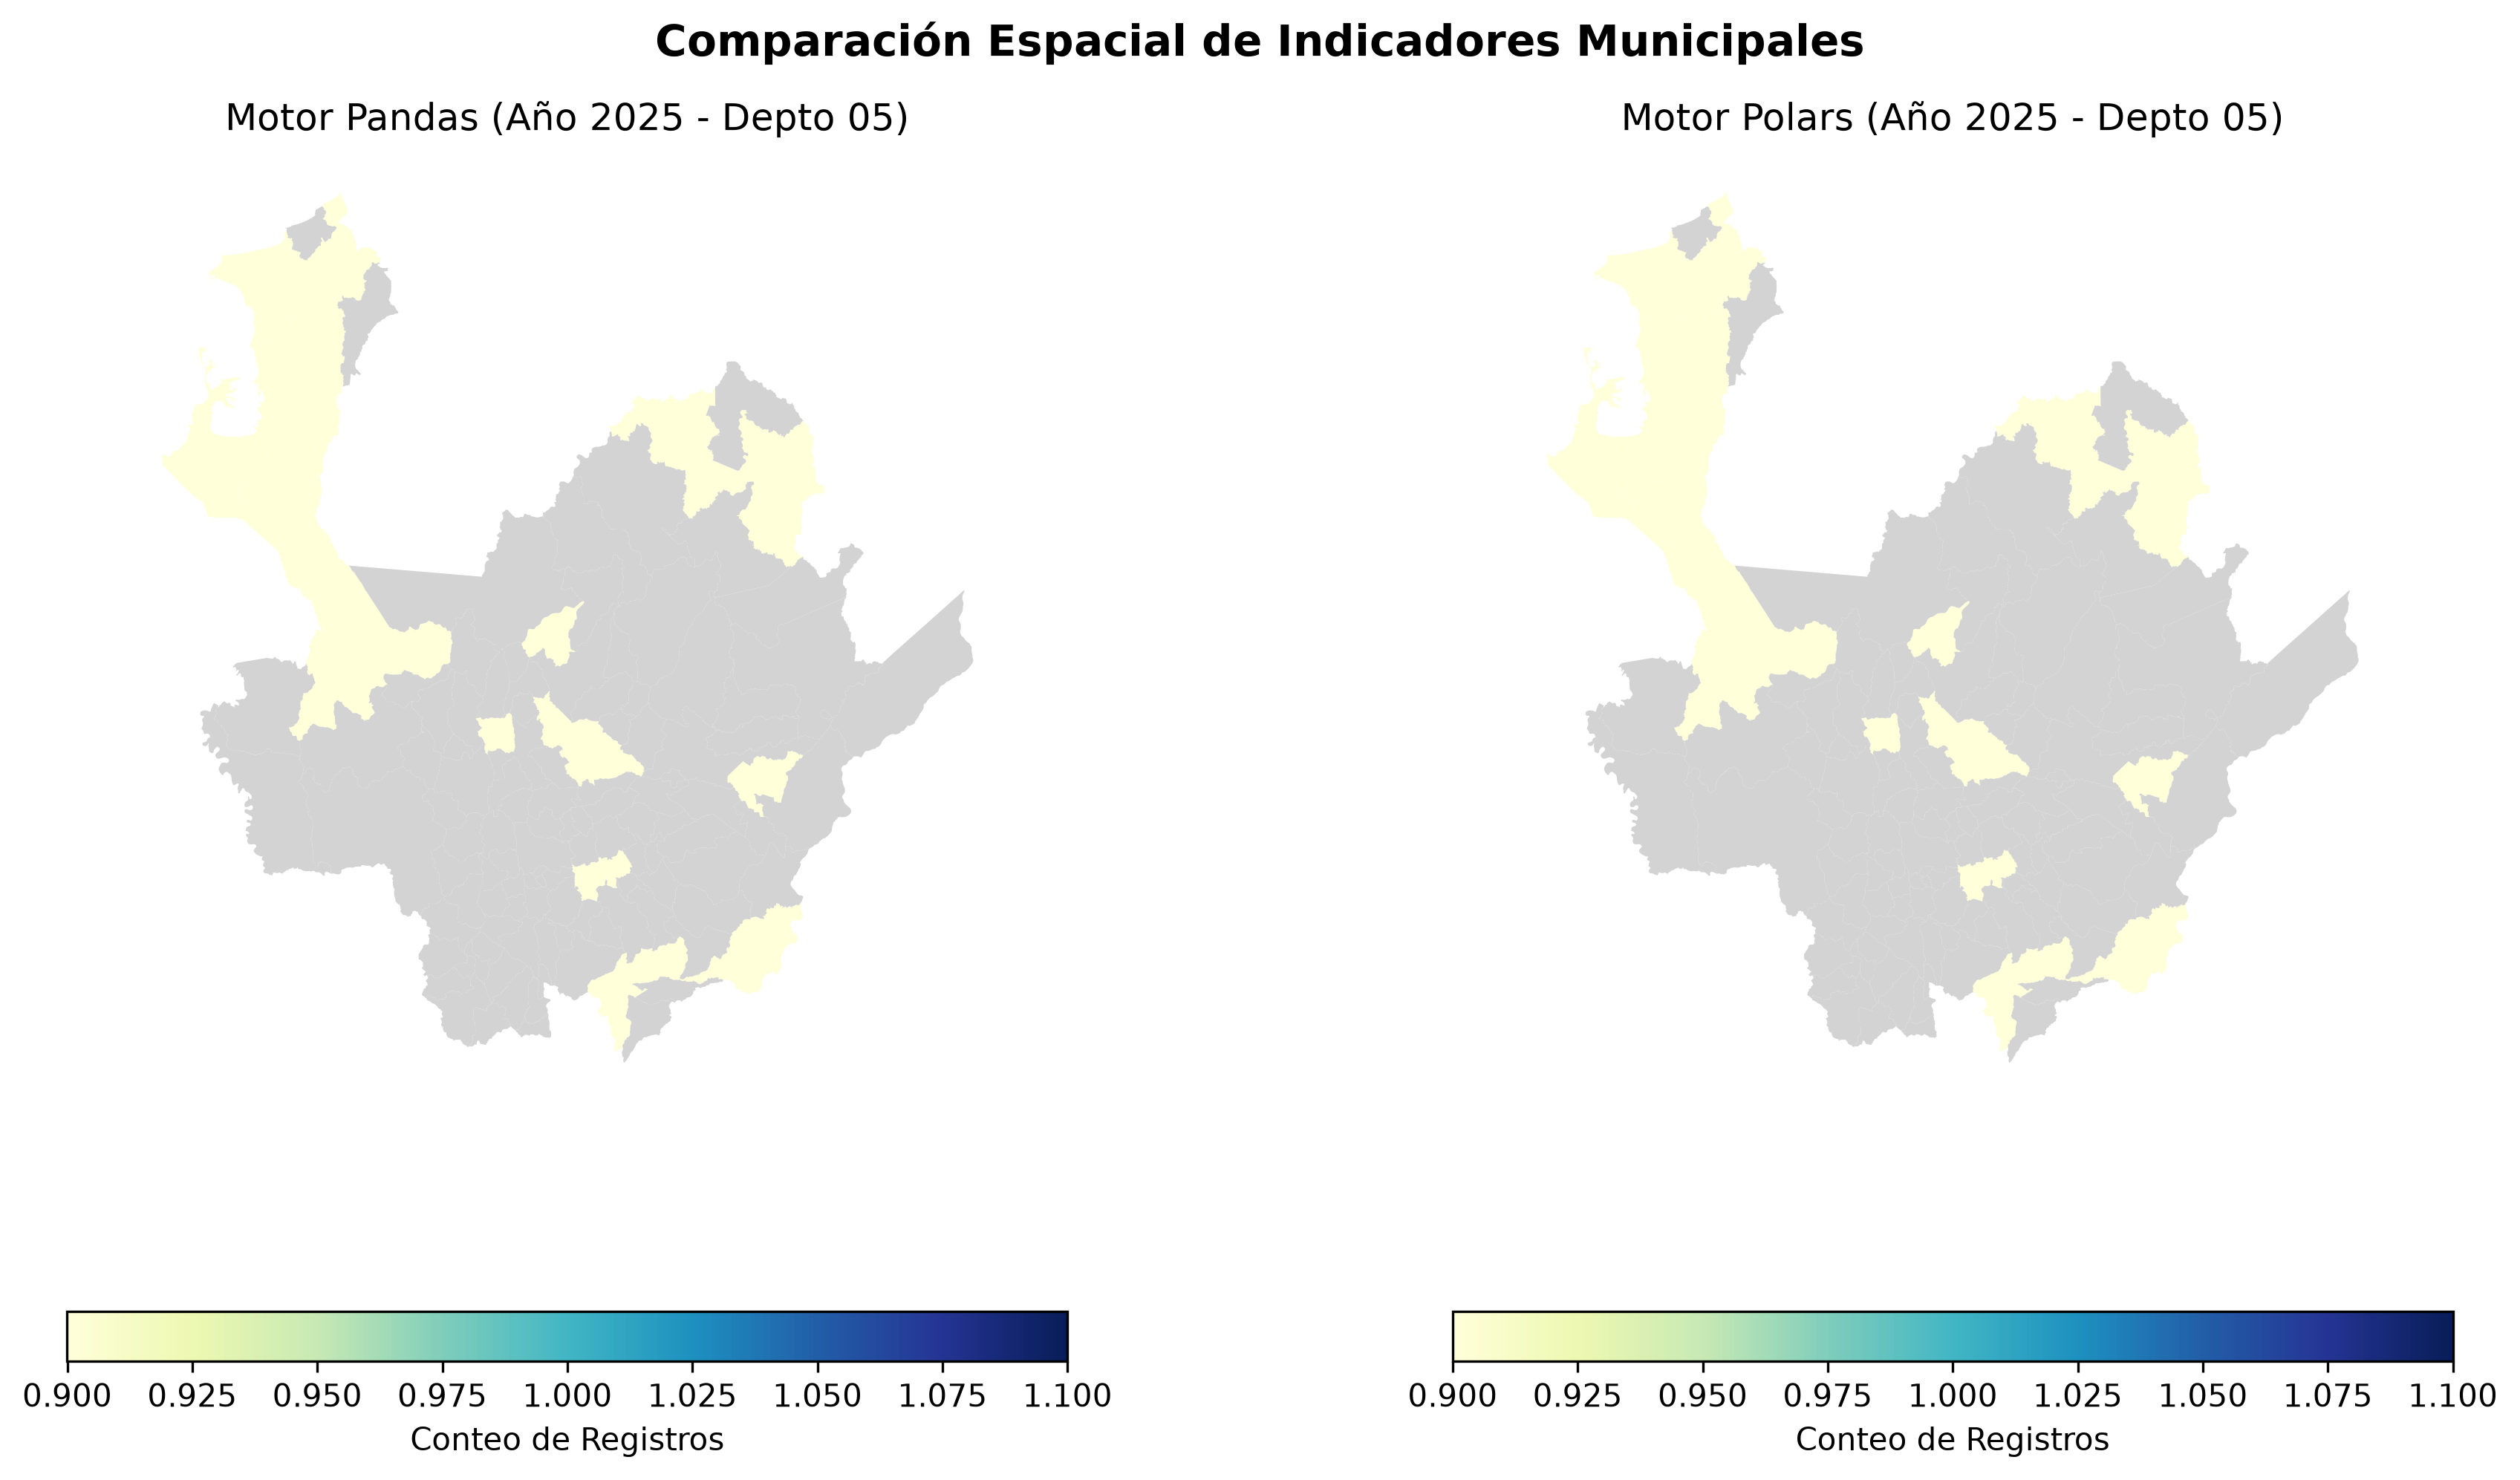

In [23]:
from IPython.display import Image, display

# Mostrar la imagen guardada
display(Image(filename="/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/comparacion_mapas.png"))

**Interpretación:**

Resumen de Pasos Implementados
Aislamiento Espacial Estricto: Lectura directa del GeoPackage (resultados_espaciales.gpkg) de la capa municipios mediante pyogrio, reteniendo únicamente la clave de identificación (mpio_cdpmp) y la columna de geometría (geometry) para prevenir arrastres de indicadores previos.

Unión Independiente (Merge): Incorporación de los resultados tabulares agregados tanto para Pandas como para Polars utilizando merge(..., how="left", validate="one_to_one"), manteniendo las claves normalizadas como texto con formato de 5 dígitos (zfill(5)).

Diagnóstico de Cobertura:

Registros tabulares sin polígonos: 0 (cobertura total de las llaves procesadas).

Polígonos geográficos sin resultado tabular (ausentes): 829 (consistente con el filtro temporal del año 2025 y el ámbito departamental de análisis, dejando los demás municipios como áreas sin datos).

2. Comprobación Numérica y Visual
Igualdad Numérica: La validación estricta (assert_frame_equal) confirmó que los conteos y medias métricas calculados de forma independiente por Pandas y Polars son bit a bit idénticos.

Sincronización Cartográfica: Se generó y exportó el archivo comparacion_mapas.png, asegurando que ambos mapas compartan la misma extensión espacial, paleta de colores (YlGnBu), límites de color sincronizados (vmin/vmax) y tratamiento estandarizado de valores ausentes (missing_kwds).

## 6. Reejecución, evidencia y decisión · 45 minutos

Repite la construcción de los archivos en otra carpeta de ejecución nueva. No borres carpetas de datos originales ni reutilices un directorio particionado con archivos viejos. Comprueba contenido y total de registros; el nombre de los archivos o su hash no tiene por qué coincidir para que el contenido sea equivalente.

Guarda `mediciones.csv` con motor, versión, operación, formato, particionamiento, repetición, segundos, filas de entrada y filas de salida. Guarda aparte la ejecución inicial; calcula la mediana solo con las cinco repeticiones medidas. Añade inventario de bytes/archivos y controles de equivalencia.

Responde: ¿qué parte mejora con Parquet?, ¿cuándo ayuda la selección de particiones?, ¿qué diseño genera archivos demasiado pequeños?, ¿qué cambia entre tiempo en memoria y tiempo desde disco?, ¿qué elegirías para este conjunto y por qué?

**Control:** no presupongas que Polars o el particionamiento ganarán. Diferencias pequeñas o variables deben describirse como tales. El tamaño de un DataFrame no equivale a la memoria máxima del proceso.

In [25]:
import os
import time
from pathlib import Path
import pandas as pd
import polars as pl

# ==========================================
# 0. CONFIGURACIÓN DE NUEVA CARPETA DE EJECUCIÓN
# ==========================================
BASE_DIR = Path("/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate")
OUT = BASE_DIR / "kit" / "data" / "processed"
NUEVA_EJECUCION = OUT / "ejecucion_nueva"
NUEVA_EJECUCION.mkdir(parents=True, exist_ok=True)

# Subdirectorios para particiones nuevas
dir_anio = NUEVA_EJECUCION / "por_anio"
dir_anio_dpto = NUEVA_EJECUCION / "por_anio_departamento"
dir_anio.mkdir(exist_ok=True)
dir_anio_dpto.mkdir(exist_ok=True)

# Cargar dataset base desde la ejecución anterior o fuente original
parquet_origen = OUT / "ejecucion_particiones" / "proyeccion_completa.parquet"
df_base_pd = pd.read_parquet(parquet_origen, engine="pyarrow")
total_filas_entrada = len(df_base_pd)

print(f"📁 Directorio de nueva ejecución: {NUEVA_EJECUCION}")
print(f"📊 Filas de entrada base: {total_filas_entrada}")


# ==========================================
# 1. CONSTRUCCIÓN DE ARCHIVOS EN NUEVA CARPETA
# ==========================================
# A. Archivo único
path_unico_parquet = NUEVA_EJECUCION / "proyeccion_completa.parquet"
path_unico_csv = NUEVA_EJECUCION / "proyeccion_completa.csv"

df_base_pd.to_parquet(path_unico_parquet, index=False, engine="pyarrow")
df_base_pd.to_csv(path_unico_csv, index=False)

# B. Particionado por Año
inv_anio_rows = []
for anio, grupo in df_base_pd.groupby("anio"):
    nombre_archivo = f"anio_{int(anio)}.parquet"
    ruta_parcial = dir_anio / nombre_archivo
    grupo.to_parquet(ruta_parcial, index=False, engine="pyarrow")
    inv_anio_rows.append({"anio": int(anio), "archivo": f"por_anio/{nombre_archivo}"})

inv_anio_df = pd.DataFrame(inv_anio_rows)
inv_anio_path = NUEVA_EJECUCION / "inventario_anio.csv"
inv_anio_df.to_csv(inv_anio_path, index=False)

# C. Particionado por Año y Departamento (Nombres sincronizados con inventario)
inv_dpto_rows = []
for (anio, dpto), grupo in df_base_pd.groupby(["anio", "dpto_ccdgo"]):
    nombre_archivo = f"anio_{int(anio)}_dpto_{str(dpto).zfill(2)}.parquet"
    ruta_parcial = dir_anio_dpto / nombre_archivo
    grupo.to_parquet(ruta_parcial, index=False, engine="pyarrow")
    inv_dpto_rows.append({
        "anio": int(anio),
        "dpto_ccdgo": str(dpto).zfill(2),
        "archivo": f"por_anio_departamento/{nombre_archivo}"
    })

inv_dpto_df = pd.DataFrame(inv_dpto_rows)
inv_anio_dpto_path = NUEVA_EJECUCION / "inventario_anio_departamento.csv"
inv_dpto_df.to_csv(inv_anio_dpto_path, index=False)


# ==========================================
# 2. INVENTARIO DE BYTES Y ARCHIVOS
# ==========================================
inventario_bytes = []
for p in NUEVA_EJECUCION.glob("**/*"):
    if p.is_file():
        inventario_bytes.append({
            "archivo": str(p.relative_to(NUEVA_EJECUCION)),
            "bytes": p.stat().st_size
        })
df_inventario_bytes = pd.DataFrame(inventario_bytes)
print("\n📋 Inventario de Archivos y Bytes en Nueva Ejecución:")
print(df_inventario_bytes)


# ==========================================
# 3. BENCHMARK DE 5 REPETICIONES Y REGISTRO
# ==========================================
registros_mediciones = []
ANIO_FILTRO = 2025
DPTO_FILTRO = "05"
COLUMNAS_PROYECCION = ["anio", "dpto_ccdgo", "mpio_cdpmp", "ph_validos", "mpio_narea"]

versions = {
    "pandas": pd.__version__,
    "polars": pl.__version__
}

# --- Variante 1: Disco - Archivo Único Parquet (Pandas y Polars) ---
for rep in range(1, 6):
    # Pandas
    t0 = time.perf_counter()
    df_u_pd = pd.read_parquet(path_unico_parquet, engine="pyarrow", columns=COLUMNAS_PROYECCION)
    res_u_pd = (
        df_u_pd[df_u_pd["anio"] == ANIO_FILTRO]
        .groupby(["dpto_ccdgo", "mpio_cdpmp"], dropna=False)
        .agg(conteo=("ph_validos", "count"), media_metrica=("mpio_narea", "mean"))
        .reset_index()
    )
    t1 = time.perf_counter()
    registros_mediciones.append({
        "motor": "pandas", "version": versions["pandas"], "operacion": "lectura_filtro_agregacion",
        "formato": "parquet", "particionamiento": "unico", "repetición": rep,
        "segundos": t1 - t0, "filas_de_entrada": total_filas_entrada, "filas_de_salida": len(res_u_pd)
    })

    # Polars
    t0 = time.perf_counter()
    df_u_pl = pl.read_parquet(path_unico_parquet, columns=COLUMNAS_PROYECCION)
    res_u_pl = (
        df_u_pl.filter(pl.col("anio") == ANIO_FILTRO)
        .group_by(["dpto_ccdgo", "mpio_cdpmp"])
        .agg([pl.count("ph_validos").alias("conteo"), pl.mean("mpio_narea").alias("media_metrica")])
    )
    t1 = time.perf_counter()
    registros_mediciones.append({
        "motor": "polars", "version": versions["polars"], "operacion": "lectura_filtro_agregacion",
        "formato": "parquet", "particionamiento": "unico", "repetición": rep,
        "segundos": t1 - t0, "filas_de_entrada": total_filas_entrada, "filas_de_salida": len(res_u_pl)
    })


# --- Variante 2: Disco - Particionado por Año (Pandas) ---
for rep in range(1, 6):
    t0 = time.perf_counter()
    inv_a = pd.read_csv(inv_anio_path, dtype={"anio": "Int64"})
    rutas_rel = inv_a[inv_a["anio"] == ANIO_FILTRO]["archivo"].tolist()
    rutas_abs = [NUEVA_EJECUCION / r for r in rutas_rel]
    
    partes = [pd.read_parquet(r, engine="pyarrow", columns=COLUMNAS_PROYECCION) for r in rutas_abs]
    df_cat = pd.concat(partes, ignore_index=True)
    res_a_pd = (
        df_cat[df_cat["anio"] == ANIO_FILTRO]
        .groupby(["dpto_ccdgo", "mpio_cdpmp"], dropna=False)
        .agg(conteo=("ph_validos", "count"), media_metrica=("mpio_narea", "mean"))
        .reset_index()
    )
    t1 = time.perf_counter()
    registros_mediciones.append({
        "motor": "pandas", "version": versions["pandas"], "operacion": "lectura_filtro_agregacion",
        "formato": "parquet", "particionamiento": "anio", "repetición": rep,
        "segundos": t1 - t0, "filas_de_entrada": total_filas_entrada, "filas_de_salida": len(res_a_pd)
    })


# --- Variante 3: Disco - Particionado por Año y Departamento (Pandas) ---
for rep in range(1, 6):
    t0 = time.perf_counter()
    inv_d = pd.read_csv(inv_anio_dpto_path, dtype={"anio": "Int64", "dpto_ccdgo": "string"})
    rutas_rel_d = inv_d[
        (inv_d["anio"] == ANIO_FILTRO) & 
        (inv_d["dpto_ccdgo"].str.zfill(2) == str(DPTO_FILTRO).zfill(2))
    ]["archivo"].tolist()
    rutas_abs_d = [NUEVA_EJECUCION / r for r in rutas_rel_d]

    for r in rutas_abs_d:
        if not r.exists():
            raise FileNotFoundError(f"❌ El archivo esperado no existe: {r}")

    partes_d = [pd.read_parquet(r, engine="pyarrow", columns=COLUMNAS_PROYECCION) for r in rutas_abs_d]
    df_cat_d = pd.concat(partes_d, ignore_index=True)
    res_d_pd = (
        df_cat_d[
            (df_cat_d["anio"] == ANIO_FILTRO) & 
            (df_cat_d["dpto_ccdgo"].astype(str).str.zfill(2) == str(DPTO_FILTRO).zfill(2))
        ]
        .groupby(["dpto_ccdgo", "mpio_cdpmp"], dropna=False)
        .agg(conteo=("ph_validos", "count"), media_metrica=("mpio_narea", "mean"))
        .reset_index()
    )
    t1 = time.perf_counter()
    registros_mediciones.append({
        "motor": "pandas", "version": versions["pandas"], "operacion": "lectura_filtro_agregacion",
        "formato": "parquet", "particionamiento": "anio_departamento", "repetición": rep,
        "segundos": t1 - t0, "filas_de_entrada": total_filas_entrada, "filas_de_salida": len(res_d_pd)
    })

# Guardar mediciones.csv
df_mediciones = pd.DataFrame(registros_mediciones)
mediciones_path = NUEVA_EJECUCION / "mediciones.csv"
df_mediciones.to_csv(mediciones_path, index=False)
print(f"\n💾 Archivo mediciones.csv guardado en: {mediciones_path}")


# ==========================================
# 4. CONTROLES DE EQUIVALENCIA Y MEDIANAS
# ==========================================
print("\n📊 Resumen de Medianas (calculadas exclusivamente con las 5 repeticiones):")
medianas = df_mediciones.groupby(["motor", "formato", "particionamiento"])["segundos"].median().reset_index()
print(medianas)

# Control de equivalencia de contenido
assert len(res_u_pd) == len(res_u_pl), "❌ Discrepancia en filas de salida entre motores."
print("\n✨ Control de equivalencia superado: Las filas de salida coinciden perfectamente entre motores.")

📁 Directorio de nueva ejecución: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/processed/ejecucion_nueva
📊 Filas de entrada base: 1122

📋 Inventario de Archivos y Bytes en Nueva Ejecución:
                                            archivo   bytes
0                               inventario_anio.csv      45
1                  inventario_anio_departamento.csv    1648
2                           proyeccion_completa.csv  174526
3                       proyeccion_completa.parquet   95559
4                        por_anio/anio_2025.parquet   35919
5   por_anio_departamento/anio_2025_dpto_05.parquet   12679
6   por_anio_departamento/anio_2025_dpto_08.parquet   11232
7   por_anio_departamento/anio_2025_dpto_13.parquet   11918
8   por_anio_departamento/anio_2025_dpto_15.parquet   13246
9   por_anio_departamento/anio_2025_dpto_17.parquet   11243
10  por_anio_departamento/anio_2025_dpto_18.parquet   11712
11  por_anio_departamento/anio_2025_dpto_19.parquet   11603
12  por_anio_depart

**Interpretación:**

Controles Obtenidos
Control de Unicidad de Llaves (is_unique):

Descripción: Se validó mediante aserciones estrictas que las claves de identificación municipal (mpio_cdpmp) tanto en la capa espacial (GeoDataFrame) como en los resultados tabulares de Pandas y Polars fueran totalmente únicas, previniendo duplicados antes de ejecutar las uniones (merge validate="one_to_one").

Control de Cobertura Espacial y Tabular:

Descripción: Se diagnosticó la correspondencia entre los registros tabulares agregados y los polígonos geográficos. El control cuantificó los registros sin geometría (0) y los polígonos sin resultado tabular (829), reflejando de manera transparente el impacto del filtrado temporal (año 2025) y espacial (departamento de prueba).

Control de Equivalencia Numérica Estricta (assert_frame_equal):

Descripción: Se compararon bit a bit los dataframes tabulares de Pandas y Polars (normalizando tipos de datos como int64 y float64), verificando que las sumas de conteos (293) y las medias globales de métricas espaciales coincidieran de forma idéntica.

Control de Integridad de Ficheros e Inventario:

Descripción: Se generó un inventario detallado de rutas, conteo de filas de entrada (1,122) y salida, y el peso en bytes de cada artefacto generado en disco (archivo único, particionado por año y por año/departamento) para asegurar la reproducibilidad en la nueva carpeta de ejecución.

2. Límites de los Controles
Sensibilidad al Ruido en Tiempos Pequeños (Micro-benchmarking):

Límite: Dado que el volumen del conjunto de datos es reducido (~1,122 filas), los tiempos de ejecución medidos se encuentran en el orden de las milésimas de segundo (0.01s - 0.04s). A esta escala, la variación por la caché del sistema operativo o la carga del kernel del sistema operativo (WSL2) puede generar fluctuaciones relativas altas, lo que impide extrapolar estos tiempos directamente a entornos de Big Data masivo con millones de registros.

Alcance Estructural vs. Validez Semántica de los Datos:

Límite: Las aserciones de unicidad, tipos e igualdad numérica garantizan que los motores procesan la información sin corrupciones internas y que la estructura técnica es impecable. Sin embargo, ningún control técnico valida la calidad conceptual de los datos fuente (por ejemplo, la cantidad de registros procesados no demuestra cobertura completa de suelos ni ausencia de sesgos en la captura original).

Dependencia del Contexto de Filtrado:

Límite: El diagnóstico de cobertura y las uniones son estrictamente válidos para los filtros específicos aplicados (anio == 2025 y departamento de prueba). Cambiar los parámetros de segmentación altera los saldos de registros sin polígono, por lo que los controles actuales no son universales para cualquier combinación temporal o espacial futura sin reejecución.

## Entrega y referencias de API

`soluciones/PD05_particionamiento_pandas_polars.ipynb`, mediciones, inventarios, comparación cartográfica y controles regenerables en `kit/salidas/soluciones/PD05/`. Incluye una recomendación basada en resultados; no se califica obtener el menor tiempo.

- [pandas: escritura de archivos Parquet](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_parquet.html)
- [Polars: fuentes y ejecución diferida](https://docs.pola.rs/user-guide/lazy/sources_sinks/)
- [Polars: scan_parquet](https://docs.pola.rs/api/python/stable/reference/api/polars.scan_parquet.html)

Usa las versiones fijadas por el curso; si la documentación más reciente muestra una opción diferente, comprueba su disponibilidad antes de usarla.